In [110]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
vermelho = [43, 53, 194]#2#5
amarelo = [46, 224, 213]#32#66
verde = [115, 174, 3]##160
azul = [210, 179, 82]#96#193

vm = (np.uint8([[vermelho]]))[0][0][0]
am = (np.uint8([[amarelo]]))[0][0][0]
vd = (np.uint8([[verde]]))[0][0][0]
az = (np.uint8([[azul]]))[0][0][0]

def choosecolor (valorhsv):
    #sobre 2 menos 1
    
    h = int(valorhsv[0])

    dist = [0,0,0,0]

    # print("aaaa")

    dist[0] = abs(h - vm)
    dist[1] = abs(h - am)
    dist[2] = abs(h - vd)
    dist[3] = abs(h - az)

    # print("bbbb")

    a = min(dist)
    # print(dist)

    # print(dist[0], dist[1], dist[2], dist[3])

    # print("current color (" + str(valorhsv[0]) + ", " + str(valorhsv[1]) + ", " + str(valorhsv[2]) + ") is closer to the color of index " + str(dist.index(a)) + " (" + str(a) + " units away)")

    return dist.index(a)






def getcolor (img, c1):

    # for c in circulos[0, :]:

    c = (int(c1[0]),int(c1[1]),int(c1[2]))

    r = int(c[2])
    hues = [0,0,0,0]
    # print(img.shape)

    for i in range(-1*r, r):
        for j in range(-1*r, r):
            if (c[0] + i < 0 or c[0] + i >= img.shape[0] or c[1] + j < 0 or c[1] + j >= img.shape[1]):
                continue
            dist = np.sqrt((i)**2 + (j)**2)
            # print("cheguei aqui 3 e a dist eh igual a " + str(dist))
            if int(dist) <= r and int(dist) >= r*2/3 : # ta dentro da area

                # print('estou no pixel ('+ str(c[0]+i) +', ' + str(c[1]+j) + ')')
                # # hues[choosecolor(img[c[0] + i][c[1] + j])]+=1
                # print('cor: ' + str(img[c[0] + i][c[1] + j]))
                a = np.uint8([[img[c[0] + i][c[1] + j]]])
                a = cv.cvtColor(a, cv.COLOR_BGR2HSV)
                # print(a)
                if (a[0][0][1] > 15): # se eh suficientemente longe do gray
                    # print(img[c[0] + i][c[1] + j])
                    # print(c[0] + i)
                    # print(c[1] + j)
                    hues[choosecolor(a[0][0])]+=1
    # print(hues)
    # print(hues)
                    
    return hues.index(max(hues))

                


    # for i in circulos[0, :]:
    # cv.circle(imgfinal, (i[0], i[1]), i[2], (0, 255, 0), 1)

    # cv.circle(imgfinal, (i[0], i[1]), int(np.around(2*i[2]/3)), (0, 255, 0), 1)

    # cv.circle(imgfinal, (i[0],i[1]), 2, (0, 0, 255), 3)

168 166 165
165 166 168
110 5 168


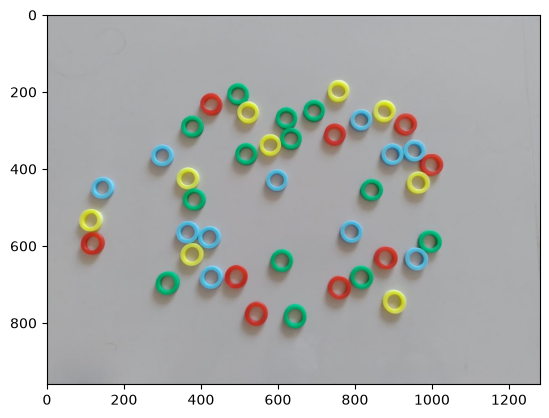

In [112]:
filepath = "../img/1.jpg"
img = cv.imread(filepath)
print(img[815][449][0], img[815][449][1], img[815][449][2])
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
print(img[815][449][0], img[815][449][1], img[815][449][2])
imghsv = cv.cvtColor(img, cv.COLOR_RGB2HSV)
print(imghsv[815][449][0], imghsv[815][449][1], imghsv[815][449][2])
# hue vai nos ajudar mais do que rgb!
imgray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
plt.imshow(img)
imgray = cv.GaussianBlur(imgray, (7, 7), 1.5)

In [113]:

teste = np.zeros((300,512,3), np.uint8)
teste = cv.cvtColor(img, cv.COLOR_BGR2HSV)
teste[:] = [102, 133, 34]#[161,74,52]
cor = [110, 5, 168]#[102, 133, 34]
corr = np.uint8([[cor]])
corr = cv.cvtColor(corr, cv.COLOR_BGR2HSV)
print(corr[0][0][0], corr[0][0][1], corr[0][0][2])
cv.imshow('', teste)
cv.waitKey(0)
cv.destroyAllWindows()

161 247 168


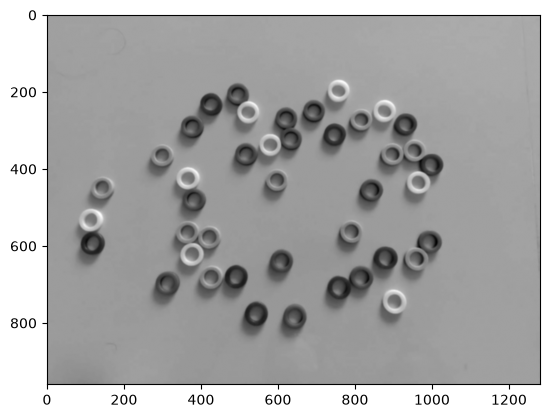

In [114]:
plt.imshow(imgray, cmap='gray')

In [115]:
circulos = cv.HoughCircles(imgray, cv.HOUGH_GRADIENT, 1, 20, param1=50, param2=30, minRadius=10, maxRadius=40)
circulosinternos = cv.HoughCircles(imgray, cv.HOUGH_GRADIENT,20, 20, param1=50, param2=50, minRadius=15, maxRadius=25)


In [116]:
circulos = np.uint16(np.around(circulos))
print(circulos.shape)
# circulosinternos = np.uint16(np.around(circulosinternos))
# print(circulosinternos.shape)

imgfinal = imghsv

# imgfinalinternos = img.copy()

cores = [0,0,0,0]

for i in circulos[0, :]:
    a = getcolor(imghsv, i)
    cor = (0,0,0)
    s = "a cor selecionada foi: "
    match a:
        case 0:
            cor = (2, 120, 255)
            cores[0]+=1
        case 1:
            cor = (32, 120, 255)
            cores[1]+=1
            # print(s + "amarelo")
        case 2:
            cor = (79, 120, 255)
            cores[2]+=1
            # print(s + "verde")
        case 3:
            cor = (96, 120, 255)
            cores[3]+=1
            # print(s + "azul")
        
    cv.circle(imgfinal, (i[0], i[1]), i[2], cor, 1)

    cv.circle(imgfinal, (i[0], i[1]), int(np.around(2*i[2]/3)), cor, 1)

    cv.circle(imgfinal, (i[0],i[1]), 2, cor, 3)
    # break;
    
    

# for i in circulosinternos[0, :]:
#     cv.circle(imgfinalinternos, (i[0], i[1]), i[2], (0, 255, 0), 1)

#     cv.circle(imgfinalinternos, (i[0],i[1]), 2, (0, 0, 255), 3)
print(cores)

(1, 42, 3)


/tmp/ipykernel_55047/26651872.py:23: RuntimeWarning: overflow encountered in scalar subtract
  dist[3] = abs(h - az)
/tmp/ipykernel_55047/26651872.py:20: RuntimeWarning: overflow encountered in scalar subtract
  dist[0] = abs(h - vm)
/tmp/ipykernel_55047/26651872.py:21: RuntimeWarning: overflow encountered in scalar subtract
  dist[1] = abs(h - am)
/tmp/ipykernel_55047/26651872.py:22: RuntimeWarning: overflow encountered in scalar subtract
  dist[2] = abs(h - vd)


[2, 0, 32, 8]


In [117]:
# print(circulos)

In [118]:
# print(circulosinternos)

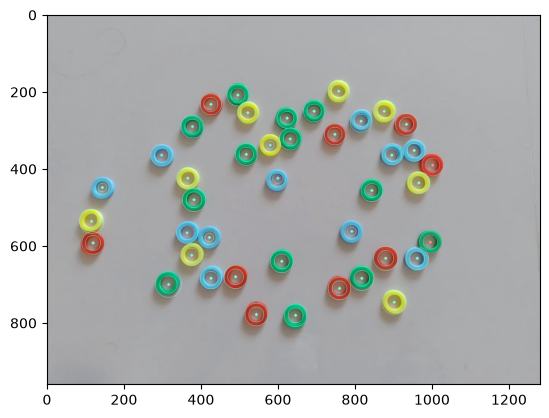

In [119]:
imgfinal = cv.cvtColor(imgfinal, cv.COLOR_HSV2RGB)
plt.imshow(imgfinal)

In [120]:
# plt.imshow(imgfinalinternos)
print(imghsv[0][0])

[110   4 174]


ok entao temos os centros, os raios possivelmente errados e a imagem em hsv

no entanto! temos que a proporcao entre o raio interno e externo eh constante

posso pegar a moda de todos os pixels? vai ser O(t*40^2)